'''

Linear Algebra For AI - Final Project Demonstration
Dataset: 1275-row samples from Kaggle's Laptop Prices dataset
Target: Laptop prices prediction based on the given specifications
Instructions: Run the notebook in a folder containing an 'archive' directory that contains the dataset file.
Dependencies: numpy, pandas, matplotlib

'''

In [160]:

# Dependencies
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.preprocessing import StandardScaler

# Load dataset
df = pd.read_csv("archive/laptop_prices.csv")

# Select independent variables
features = [
    "Inches",
    "Ram",
    "Weight",
    "ScreenW",
    "ScreenH",
    "CPU_freq",
    "PrimaryStorage",
    "SecondaryStorage"
]

# Select the target variable
target = "Price_euros"

# Create selected dataset
data = df[features + [target]].copy()

# Convert laptop prices from EUR to PHP
EUR_TO_PHP = 68.00
data[target] = data[target] * EUR_TO_PHP

# Display information
print("Dataset Shape:", data.shape)

# 1. Separate the features and target
X = data[features].to_numpy(dtype=float)
y = data[target].to_numpy(dtype=float)

# 2. Create a reproducible 80/20 split
rng = np.random.default_rng(42)

indices = rng.permutation(len(data))

n_test = int(0.20 * len(data))

test_indices = indices[:n_test]
train_indices = indices[n_test:]

# 3. Construct training and testing matrices
X_train = X[train_indices]
X_test = X[test_indices]

y_train = y[train_indices]
y_test = y[test_indices]

# 4. Calculate the transpose
X_train_T = X_train.T

# 5. Calculate X transpose multiplied by X
XTX = X_train_T @ X_train

# 6. Display the dimensions
print("Original X:", X.shape)
print("Original y:", y.shape)

print("\nTraining Data:")
print("X_train:", X_train.shape)
print("y_train:", y_train.shape)

print("\nTesting Data:")
print("X_test:", X_test.shape)
print("y_test:", y_test.shape)

print("\nTranspose:")
print("X_train_T:", X_train_T.shape)

print("\nGram Matrix:")
print("XTX:", XTX.shape)

# Verify conversion
print("\nFirst 5 target values (PHP):")
print(y[:5])


Dataset Shape: (1275, 9)
Original X: (1275, 8)
Original y: (1275,)

Training Data:
X_train: (1020, 8)
y_train: (1020,)

Testing Data:
X_test: (255, 8)
y_test: (255,)

Transpose:
X_train_T: (8, 1020)

Gram Matrix:
XTX: (8, 8)

First 5 target values (PHP):
[ 91098.92  61127.92  39100.   172546.6  122644.8 ]


Part B: Matrix Representation

In [161]:
# Give the Gram matrix readable row and column names
XTX_df = pd.DataFrame(
    XTX,
    index=features,
    columns=features
)

display(XTX_df.round(2))

,Inches,Ram,Weight,ScreenW,ScreenH,CPU_freq,PrimaryStorage,SecondaryStorage
Inches,232376.84,130865.80,32048.52,2.902692e+07,1.639479e+07,35666.35,7.010784e+06,2.941992e+06
Ram,130865.80,98388.00,18754.32,1.734529e+07,9.803488e+06,20860.72,3.893912e+06,2.303808e+06
Weight,32048.52,18754.32,4687.99,3.937674e+06,2.221315e+06,4912.24,9.756331e+05,5.003755e+05
ScreenW,29026921.20,17345292.00,3937674.40,3.897741e+09,2.204434e+09,4528094.00,8.534397e+08,3.762944e+08
ScreenH,16394785.60,9803488.00,2221314.66,2.204434e+09,1.247724e+09,2558099.60,4.814863e+08,2.116656e+08
CPU_freq,35666.35,20860.72,4912.24,4.528094e+06,2.558100e+06,5715.11,1.067989e+06,4.666548e+05
PrimaryStorage,7010784.40,3893912.00,975633.07,8.534397e+08,4.814863e+08,1067989.12,3.449701e+08,4.213350e+07
SecondaryStorage,2941992.40,2303808.00,500375.46,3.762944e+08,2.116656e+08,466654.80,4.213350e+07,2.085768e+08


In [162]:
# 7. Demonstrate the rank-one update

# Get one actual laptop observation from the test set
new_row = X_test[0]

# Calculate the outer product of the new observation
rank_one_update = np.outer(new_row, new_row)

# Update the original Gram matrix
XTX_updated = XTX + rank_one_update

# Verify by directly adding the new row to the training matrix
X_train_with_new_row = np.vstack((X_train, new_row))

XTX_check = X_train_with_new_row.T @ X_train_with_new_row

# Display the results
print("New observation shape:", new_row.shape)
print("Rank-one update shape:", rank_one_update.shape)
print("Updated training matrix:", X_train_with_new_row.shape)
print("Updated Gram matrix:", XTX_updated.shape)

print("\nDoes the rank-one update match the recalculated Gram matrix?")
print(np.allclose(XTX_updated, XTX_check))

New observation shape: (8,)
Rank-one update shape: (8, 8)
Updated training matrix: (1021, 8)
Updated Gram matrix: (8, 8)

Does the rank-one update match the recalculated Gram matrix?
True


In [163]:
# 8. Vector Spaces and Feature Dependence

# Get the dimensions of the training matrix
n, p = X_train.shape

# Calculate the rank
rank_X = np.linalg.matrix_rank(X_train)

print("Number of observations:", n)
print("Number of features:", p)
print("Rank of training matrix:", rank_X)

# Check linear independence
if rank_X == p:
    print("The feature columns are linearly independent.")
else:
    print("The feature columns are linearly dependent.")

Number of observations: 1020
Number of features: 8
Rank of training matrix: 8
The feature columns are linearly independent.


### 3.3 Data Transformations: Standardization

Standardization is applied to transform the numerical features into a common scale. The training dataset is used to calculate the mean and standard deviation, which are then applied to both training and testing datasets.

In [164]:
# 9. Standardization

# Create the scaler
scaler = StandardScaler()

# Fit using training data and transform it
X_train_std = scaler.fit_transform(X_train)

# Transform testing data using training statistics
X_test_std = scaler.transform(X_test)

# Create the diagonal scaling matrix
M = np.diag(1.0 / scaler.scale_)

# Display results
print("Training means:", scaler.mean_)
print("\nTraining standard deviations:", scaler.scale_)

print("\nDiagonal scaling matrix M:")
print(M)

print("\nFirst test raw vector:")
print(X_test[0])

print("\nFirst test standardized vector:")
print(X_test_std[0])

print("\nDeterminant of M:")
print(np.linalg.det(M))

print("Standardized training means:")
print(np.mean(X_train_std, axis=0))

print("\nStandardized training standard deviations:")
print(np.std(X_train_std, axis=0))

Training means: [  15.02745098    8.42941176    2.03928235 1896.18235294 1071.65098039
    2.31401961  448.16078431  176.91764706]

Training standard deviations: [  1.41285116   5.0402223    0.66135927 475.19143107 273.53727163
   0.49836116 370.61829319 416.15766842]

Diagonal scaling matrix M:
[[0.70778864 0.         0.         0.         0.         0.
  0.         0.        ]
 [0.         0.19840395 0.         0.         0.         0.
  0.         0.        ]
 [0.         0.         1.51203747 0.         0.         0.
  0.         0.        ]
 [0.         0.         0.         0.00210442 0.         0.
  0.         0.        ]
 [0.         0.         0.         0.         0.00365581 0.
  0.         0.        ]
 [0.         0.         0.         0.         0.         2.00657693
  0.         0.        ]
 [0.         0.         0.         0.         0.         0.
  0.00269819 0.        ]
 [0.         0.         0.         0.         0.         0.
  0.         0.00240294]]

First test ra

### 3.4 Determinants, Conditioning, and Stable Solutions

In [165]:
# 10. Determinants and Conditioning

# Create the Gram matrix using standardized training data
G = X_train_std.T @ X_train_std

# Calculate determinant
det_G = np.linalg.det(G)

# Calculate condition number
cond_G = np.linalg.cond(G)

# Calculate rank
rank_G = np.linalg.matrix_rank(G)

print("Gram Matrix Shape:", G.shape)
print("\nDeterminant of G:", det_G)
print("\nCondition Number of G:", cond_G)
print("\nRank of G:", rank_G)

Gram Matrix Shape: (8, 8)

Determinant of G: 1.3381488410628165e+21

Condition Number of G: 466.8662462154778

Rank of G: 8


### 3.5 Eigenvalues, Eigenvectors, and Covariance Matrix

In [166]:
# 11. Covariance Matrix and Eigendecomposition

# Calculate covariance matrix
C = np.cov(X_train_std, rowvar=False)

# Calculate eigenvalues and eigenvectors
eigenvalues, eigenvectors = np.linalg.eigh(C)

# Sort eigenvalues in descending order
order = np.argsort(eigenvalues)[::-1]

eigenvalues = eigenvalues[order]
eigenvectors = eigenvectors[:, order]

# Calculate explained variance ratio
variance_ratio = eigenvalues / eigenvalues.sum()

# Calculate cumulative explained variance
cumulative_variance = np.cumsum(variance_ratio)

print("Covariance Matrix Shape:", C.shape)

print("\nEigenvalues:")
print(eigenvalues)

print("\nExplained Variance Ratio:")
print(variance_ratio)

print("\nCumulative Explained Variance:")
print(cumulative_variance)

# 12. Verify the Eigenvalue-Eigenvector Relationship

v1 = eigenvectors[:, 0]

eigenvector_check = C @ v1
expected_result = eigenvalues[0] * v1

residual = np.linalg.norm(eigenvector_check - expected_result)

print("First Eigenvalue:", eigenvalues[0])
print("Eigenvector Residual:", residual)

Covariance Matrix Shape: (8, 8)

Eigenvalues:
[2.79357845 2.1351907  1.16815153 0.77903847 0.55648622 0.41652883
 0.15289294 0.00598368]

Explained Variance Ratio:
[0.34885496 0.26663717 0.14587579 0.09728434 0.06949258 0.05201506
 0.01909288 0.00074723]

Cumulative Explained Variance:
[0.34885496 0.61549213 0.76136791 0.85865225 0.92814483 0.98015989
 0.99925277 1.        ]
First Eigenvalue: 2.793578453928466
Eigenvector Residual: 8.496108186436517e-16


In [167]:
# 13. Diagonalization

# Store eigenvectors in V
V = eigenvectors

# Create diagonal eigenvalue matrix
Lambda = np.diag(eigenvalues)

# Reconstruct covariance matrix
C_reconstructed = V @ Lambda @ V.T

# Calculate reconstruction error
reconstruction_error = np.linalg.norm(
    C - C_reconstructed,
    ord="fro"
)

print("Eigenvector Matrix Shape:", V.shape)
print("Diagonal Matrix Shape:", Lambda.shape)
print("Reconstructed Covariance Matrix Shape:", C_reconstructed.shape)

print("\nReconstruction Error:")
print(reconstruction_error)

# 14. Select Principal Components

# Determine the number of components needed for 95% variance
k = int(np.argmax(cumulative_variance >= 0.95) + 1)

# Select the first k eigenvectors
V_k = V[:, :k]

print("Required Variance:", 95, "%")
print("Selected Components:", k)
print("Retained Variance:", cumulative_variance[k-1] * 100, "%")
print("Selected Eigenvector Matrix Shape:", V_k.shape)

# 14. Select Principal Components

# Determine the number of components needed for 95% variance
k = int(np.argmax(cumulative_variance >= 0.95) + 1)

# Select the first k eigenvectors
V_k = V[:, :k]

print("Required Variance:", 95, "%")
print("Selected Components:", k)
print("Retained Variance:", cumulative_variance[k-1] * 100, "%")
print("Selected Eigenvector Matrix Shape:", V_k.shape)

# 15. PCA Transformation

# Project training and testing data
X_train_pca = X_train_std @ V_k
X_test_pca = X_test_std @ V_k

print("Original Training Shape:", X_train_std.shape)
print("PCA Training Shape:", X_train_pca.shape)

print("\nOriginal Testing Shape:", X_test_std.shape)
print("PCA Testing Shape:", X_test_pca.shape)

Eigenvector Matrix Shape: (8, 8)
Diagonal Matrix Shape: (8, 8)
Reconstructed Covariance Matrix Shape: (8, 8)

Reconstruction Error:
7.550316124213409e-15
Required Variance: 95 %
Selected Components: 6
Retained Variance: 98.01598922845152 %
Selected Eigenvector Matrix Shape: (8, 6)
Required Variance: 95 %
Selected Components: 6
Retained Variance: 98.01598922845152 %
Selected Eigenvector Matrix Shape: (8, 6)
Original Training Shape: (1020, 8)
PCA Training Shape: (1020, 6)

Original Testing Shape: (255, 8)
PCA Testing Shape: (255, 6)


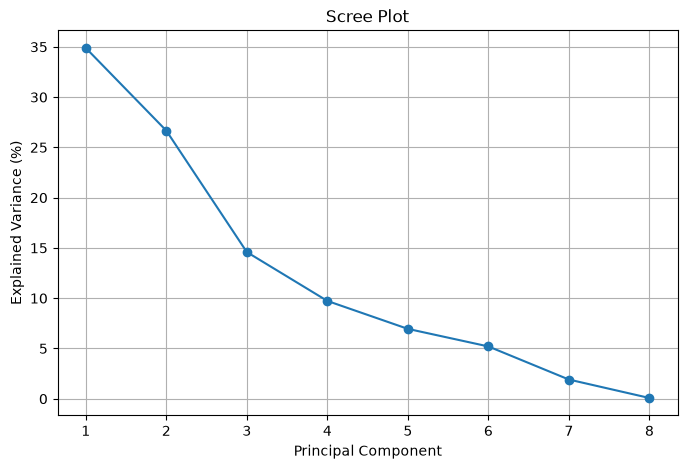

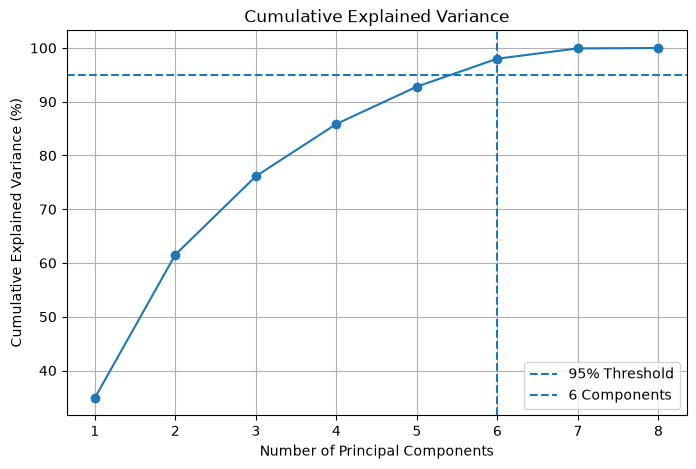

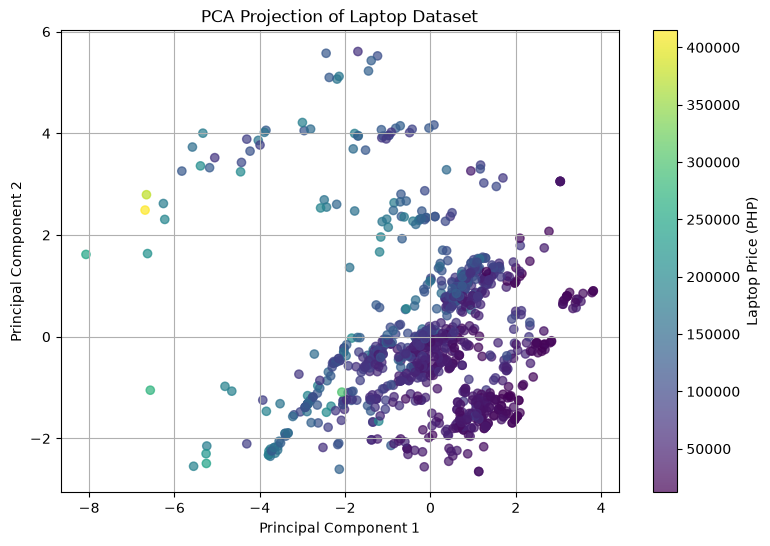

In [168]:
# 16. Scree Plot

plt.figure(figsize=(8, 5))

plt.plot(
    range(1, len(eigenvalues) + 1),
    variance_ratio * 100,
    marker='o'
)

plt.xlabel("Principal Component")
plt.ylabel("Explained Variance (%)")
plt.title("Scree Plot")
plt.xticks(range(1, len(eigenvalues) + 1))
plt.grid(True)

plt.show()

# 17. Cumulative Explained Variance Plot

plt.figure(figsize=(8, 5))

plt.plot(
    range(1, len(cumulative_variance) + 1),
    cumulative_variance * 100,
    marker='o'
)

plt.axhline(y=95, linestyle='--', label='95% Threshold')
plt.axvline(x=k, linestyle='--', label=f'{k} Components')

plt.xlabel("Number of Principal Components")
plt.ylabel("Cumulative Explained Variance (%)")
plt.title("Cumulative Explained Variance")
plt.xticks(range(1, len(eigenvalues) + 1))
plt.legend()
plt.grid(True)

plt.show()

# 18. PCA Projection

plt.figure(figsize=(9, 6))

scatter = plt.scatter(
    X_train_pca[:, 0],
    X_train_pca[:, 1],
    c=y_train,
    cmap='viridis',
    alpha=0.7
)

plt.colorbar(scatter, label="Laptop Price (PHP)")

plt.xlabel("Principal Component 1")
plt.ylabel("Principal Component 2")
plt.title("PCA Projection of Laptop Dataset")

plt.grid(True)
plt.show()

### 4. AI Model Development and Evaluation

#### 4.1 Ordinary Least Squares Regression

In [169]:
# 19. OLS Regression Functions

def fit_ols(A, target):
    # Add a column of ones for the intercept
    A_bias = np.column_stack([np.ones(A.shape[0]), A])

    # Calculate regression coefficients
    beta, *_ = np.linalg.lstsq(A_bias, target, rcond=None)

    return beta


def predict(A, beta):
    # Add a column of ones for the intercept
    A_bias = np.column_stack([np.ones(A.shape[0]), A])

    # Calculate predicted values
    return A_bias @ beta

# 20. Train Full OLS and PCA-OLS Models

# Full OLS using all 8 standardized features
beta_full = fit_ols(X_train_std, y_train)

# PCA-OLS using 6 principal components
beta_pca = fit_ols(X_train_pca, y_train)

print("Full OLS Coefficients:")
print(beta_full)

print("\nPCA-OLS Coefficients:")
print(beta_pca)

Full OLS Coefficients:
[76911.86733333 -5898.04844371 26054.66633277  3854.689424
 -4490.63491184 17068.07477208  9859.88259305 -5689.53734033
  -970.28074513]

PCA-OLS Coefficients:
[ 76911.86733333 -18341.7735625   10895.65072795  -1184.99228721
 -11536.78078082  16297.27512774   8614.66952068]


In [170]:
# 21. Generate Predictions

# Full OLS predictions
y_pred_full = predict(X_test_std, beta_full)

# PCA-OLS predictions
y_pred_pca = predict(X_test_pca, beta_pca)

print("Actual Laptop Prices:")
print(y_test[:10])

print("\nFull OLS Predicted Prices:")
print(y_pred_full[:10])

print("\nPCA-OLS Predicted Prices:")
print(y_pred_pca[:10])

# 22. Model Evaluation

# Full OLS Evaluation
rmse_full = np.sqrt(np.mean((y_test - y_pred_full) ** 2))

ss_res_full = np.sum((y_test - y_pred_full) ** 2)
ss_tot = np.sum((y_test - np.mean(y_test)) ** 2)

r2_full = 1 - (ss_res_full / ss_tot)


# PCA-OLS Evaluation
rmse_pca = np.sqrt(np.mean((y_test - y_pred_pca) ** 2))

ss_res_pca = np.sum((y_test - y_pred_pca) ** 2)

r2_pca = 1 - (ss_res_pca / ss_tot)


# Display Results
print("FULL OLS MODEL")
print("RMSE:", rmse_full)
print("R²:", r2_full)

print("\nPCA-OLS MODEL")
print("RMSE:", rmse_pca)
print("R²:", r2_pca)

Actual Laptop Prices:
[185572.    63104.    39372.    44812.68  64260.   100572.    16659.32
  42092.   129132.    27132.  ]

Full OLS Predicted Prices:
[127738.11096276  57422.14782795  70237.8435748   72743.53091209
  86090.16858824 127927.17808015  40068.12490097  83162.47863231
  58862.7614661   61864.13503577]

PCA-OLS Predicted Prices:
[124240.85725662  59409.8897246   70460.92841063  72663.29336409
  84965.3516645  127711.76658482  41620.33083308  83954.40202464
  59857.97822212  61965.03724502]
FULL OLS MODEL
RMSE: 31568.38399589308
R²: 0.6244183252429658

PCA-OLS MODEL
RMSE: 31555.66745804296
R²: 0.6247208517591953


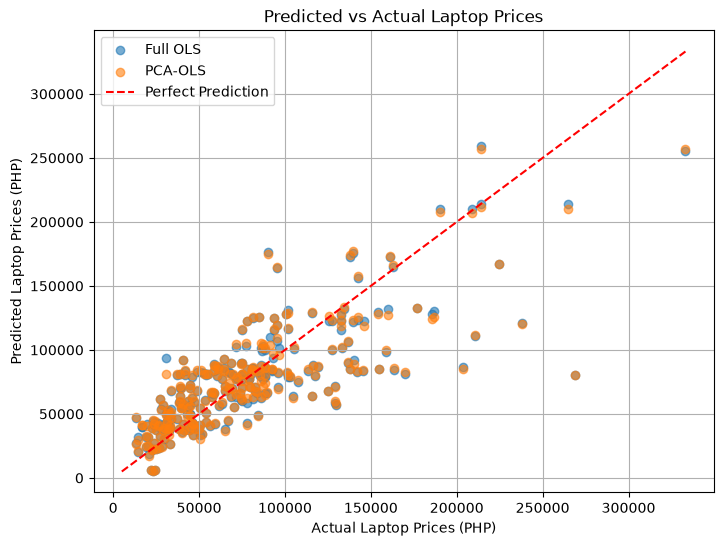

In [171]:
# 23. Predicted vs Actual Prices

plt.figure(figsize=(8, 6))

plt.scatter(
    y_test,
    y_pred_full,
    alpha=0.6,
    label="Full OLS"
)

plt.scatter(
    y_test,
    y_pred_pca,
    alpha=0.6,
    label="PCA-OLS"
)

# Perfect prediction reference line
min_price = min(y_test.min(), y_pred_full.min(), y_pred_pca.min())
max_price = max(y_test.max(), y_pred_full.max(), y_pred_pca.max())

plt.plot(
    [min_price, max_price],
    [min_price, max_price],
    linestyle="--",
    color="red",
    label="Perfect Prediction"
)

plt.xlabel("Actual Laptop Prices (PHP)")
plt.ylabel("Predicted Laptop Prices (PHP)")
plt.title("Predicted vs Actual Laptop Prices")

plt.legend()
plt.grid(True)
plt.show()

In [172]:
print("First 5 target values:")
print(y[:5])

print("\nFirst 5 actual test prices:")
print(y_test[:5])

print("\nFirst 5 predicted prices:")
print(y_pred_full[:5])

First 5 target values:
[ 91098.92  61127.92  39100.   172546.6  122644.8 ]

First 5 actual test prices:
[185572.    63104.    39372.    44812.68  64260.  ]

First 5 predicted prices:
[127738.11096276  57422.14782795  70237.8435748   72743.53091209
  86090.16858824]
